# Whole embryo or 3D geometry? Follow-up tests across pairs

The 2D cost ablation (`section_cost_ablation.ipynb`, X4) found that the features carry the cross-species signal and that space (GW) never helps in 2D. It also found that feature-only OT of each section against **all spots of the other embryo** (semi-relaxed, τ_b = 0.7) reaches κ_bal 0.475, above the 3D pipeline `PC_fgw` (0.440). That comparison changes five things at once: the GW term, the marginals, the resolution (`PC_fgw` uses 6000 points per embryo), the slab masses, and one joint solve against one solve per section. This notebook separates them and repeats the test on three pairs.

It answers five questions:
1. **Solver tolerance.** Is a looser Sinkhorn threshold safe? The benchmark's 1e-7 is never reached, so every inner solve runs to its iteration cap.
2. **3D geometry.** `PC_fgw` against `PC_w`: the same pipeline (stack points, slab masses, τ, mapping back to the spots) without the GW term. Wasserstein on the features uses no coordinates, so `PC_w` uses nothing from stage 1 but the slab masses.
3. **Marginals and resolution inside 3D.** `PC_w` with the query side balanced (`PC_w_semi@τ_b`), and `PC_w` on more points.
4. **Whole embryo on more pairs.** `E_w`, each query section against all spots of the other embryo, on X1, X4 and X5.
5. **Label-free choices.** Can τ_b be chosen by the held-out genes instead of the labels, and do cheap changes to the features help?

**Before the first run:** the pair features must exist (`python -m mgw.bench prepare --tier screen --pairs X5 --seeds 0`); the stacks are built and cached on first use (stage 1, a few minutes per embryo). Results are cached per pair in `<root>/diag/whole_embryo/`, so the notebook can be re-run, or run one pair at a time.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = os.environ["MKL_NUM_THREADS"] = os.environ["OPENBLAS_NUM_THREADS"] = "8"
os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform"   # return JAX's GPU memory after each solve

import sys
sys.path.append("..")

In [2]:
# ============================================================
# Run settings (papermill parameters)
# ============================================================
PAIRS = ("X1", "X4", "X5")       # cross pairs of bench/configs/series.yaml (a = human, b = mouse)
SEED = 0
CONFIG = "bench.yaml"            # benchmark config (bench/configs)
ROOT = None                      # benchmark root; None: $MGW_BENCH_DIR or <data dir>/bench
PIPELINE = "PC_fgw"              # the 3D pipeline whose stacks, point clouds and settings are used
TOL_PAIR = "X4"                  # the pair of the tolerance check
INNER_TOLS = (1e-7, 1e-6, 1e-5)  # Sinkhorn thresholds to test; the first is the benchmark's
TOL_MAX_DIFF = 0.005             # largest change in kappa_bal and gene r per query a looser threshold may cause
TAUS_B = (0.95, 0.9, 0.7, 0.5)   # target-side relaxation of the semi-relaxed runs (the query side balanced)
PC_N_LARGE = 20000               # points per embryo of PC_w at higher resolution (PIPELINE uses n_samples)
FEAT_TAU_B = 0.9                 # tau_b of the feature variants and of the E_w reference in the verdict
GENE_SPLIT_SEED = 0              # splits the held-out genes into a selection half and an evaluation half
FORCE = False                    # recompute pairs whose results are cached

In [3]:
import dataclasses
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from ott.geometry import geometry
from ott.problems.linear import linear_problem
from ott.solvers.linear import sinkhorn
from scipy.spatial.distance import cdist

from mgw import crossspecies as cs
from mgw.bench import config, metrics, prepare, series, solvers, store, volume
from mgw.bench.pipelines import volume as volume_pipeline
from mgw.bench.pipelines.common import Task

root = prepare.bench_root(ROOT)
cfg = config.load(CONFIG)
ser = series.load(cfg.series_path())
missing = [pid for pid in dict.fromkeys((TOL_PAIR, *PAIRS))
           if not prepare.feature_file(root, pid, SEED, cfg.feature_hash()).exists()]
if missing:
    raise FileNotFoundError(f"no features for {missing} at seed {SEED}; run first: python -m mgw.bench prepare "
                            f"--tier screen --pairs {','.join(missing)} --seeds {SEED}")
OUT = root / "diag" / "whole_embryo"
OUT.mkdir(parents=True, exist_ok=True)
# the cache key: every setting that changes a pair's rows
RUN_KEY = config.short_hash(dict(pipeline=cfg.pipeline_hash(PIPELINE), taus_b=TAUS_B, n_large=PC_N_LARGE,
                                 feat_tau_b=FEAT_TAU_B, gene_split=GENE_SPLIT_SEED))
print(f"root {root}\npairs {PAIRS}, seed {SEED}; results cached in {OUT}")

root /nas/lnt/ga79jin/MGW/data/bench
pairs ('X1', 'X4', 'X5'), seed 0; results cached in /nas/lnt/ga79jin/MGW/data/bench/diag/whole_embryo


## Helpers

From `section_cost_ablation.ipynb`: the label cost, entropic OT on the cross cost alone (`ot`, now with masses and either side relaxed), the soft nearest neighbour (`softmax_nn`, τ_b → 0) and the scores. Each coupling is scored per query section:
- **κ_bal** as in the benchmark (K: the organs of the whole target embryo);
- **gene r** on all 500 held-out genes, and on two fixed halves of them: **gene_r_sel** may choose settings (§5), **gene_r_eval** scores the choice;
- **target_used**, exp(entropy) of the target marginal over the number of target spots, and **dL**, the mass-weighted |L_target − L_query|.

The 3D couplings are mapped back to the real spots exactly as `pipelines/volume.py` does (`score_volume`).

In [4]:
f_cfg = cfg.raw["features"]


def label_cost(comp_a, comp_b):
    """Organ-label cross cost: 0 same organ, 1 different organs, 0.5 when a side is Other/Excluded."""
    Ka, Kb = metrics.row_normalize(comp_a)[:, metrics.SCORED], metrics.row_normalize(comp_b)[:, metrics.SCORED]
    return 1 - Ka @ Kb.T - 0.5 * (1 - np.outer(Ka.sum(1), Kb.sum(1)))


def ot(M, p, a=None, b=None, tau_a=1.0, tau_b=1.0, epsilon=None):
    """Entropic OT on the cross cost alone: masses a, b (default uniform), unbalanced for tau < 1. (P float32, info)"""
    t0 = time.perf_counter()
    geom = geometry.Geometry(cost_matrix=jnp.asarray(M, dtype=jnp.float32), epsilon=epsilon or p.epsilon)
    a, b = (None if x is None else jnp.asarray(x / np.sum(x), dtype=jnp.float32) for x in (a, b))
    out = sinkhorn.Sinkhorn(max_iterations=p.inner_maxit, threshold=p.inner_tol)(
        linear_problem.LinearProblem(geom, a=a, b=b, tau_a=tau_a, tau_b=tau_b))
    return np.asarray(out.matrix, dtype=np.float32), dict(converged=bool(out.converged),
                                                          seconds=time.perf_counter() - t0)


def softmax_nn(M, eps):
    """tau_b -> 0: each query spot spreads its mass over the target by exp(-M / eps); the target marginal is free."""
    L = -np.asarray(M, dtype=np.float32) / eps
    P = np.exp(L - L.max(1, keepdims=True))
    return P / P.sum(1, keepdims=True) / len(P)


def target_used(P):
    """exp(entropy) of the target marginal over the number of target spots: 1 when every spot gets the same mass."""
    b = np.asarray(P.sum(0), dtype=np.float64)
    b = b[b > 0] / b.sum()
    return float(np.exp(-(b * np.log(b)).sum()) / P.shape[1])


def gene_halves(n):
    """Two fixed halves of the held-out genes: (selection, evaluation)."""
    perm = np.random.default_rng(GENE_SPLIT_SEED).permutation(n)
    return np.sort(perm[:n // 2]), np.sort(perm[n // 2:])


def evaluate(task, d, q, tname, T, Yt, Lt, Pq):
    """The scores of a coupling Pq (rows: the spots of query section q) against target compositions T, held-out
    genes Yt and laterality Lt (per target column)."""
    r, r0 = cs.coexpression(Pq, q.Y, Yt, seed=SEED)
    sel, ev = gene_halves(len(r))
    b, ok = np.asarray(Pq.sum(0), dtype=np.float64), np.isfinite(Lt)
    dL = float((b[ok] * np.abs(Lt[ok] - q.L)).sum() / b[ok].sum()) if ok.any() and np.isfinite(q.L) else np.nan
    return dict(kappa_bal=task.score(d, q, tname, T, Pq, keep=False)["kappa_bal"],
                gene_r=np.nanmean(r) - np.nanmean(r0), gene_r_sel=np.nanmean(r[sel]) - np.nanmean(r0[sel]),
                gene_r_eval=np.nanmean(r[ev]) - np.nanmean(r0[ev]), target_used=target_used(Pq), dL=dL)


def cost_scale(Fa, Fb, metric="euclidean"):
    """The benchmark's cost scale (solvers.cost_scale: a quantile of the a x b distances), for any metric."""
    if metric == "euclidean":
        return solvers.cost_scale(Fa, Fb, f_cfg["m_scale_quantile"], f_cfg["m_scale_max_entries"], seed=SEED)
    n_cols = max(1, min(len(Fb), f_cfg["m_scale_max_entries"] // max(len(Fa), 1)))
    if n_cols < len(Fb):
        Fb = Fb[np.random.default_rng(SEED).choice(len(Fb), n_cols, replace=False)]
    return float(np.quantile(cdist(Fa, Fb, metric), f_cfg["m_scale_quantile"]))

In [5]:
def load(pid):
    """A pair's task (data, cost scale and settings of PIPELINE) and the point clouds of both stacks (stage 1)."""
    pair = ser.pairs[pid]
    task = Task(cfg, PIPELINE, pair, SEED, root)
    sides = {"a": volume_pipeline._side(task, "a_stack"), "b": volume_pipeline._side(task, "b_stack")}
    return dict(pair=pair, task=task, sides=sides, p=task.spec["params"])


def score_volume(ctx, Pdir, run, sides=None):
    """One row per (direction, query section) of the 3D couplings Pdir ({direction: P}, rows: the query side's
    points), mapped back to the real spots as in pipelines/volume.py."""
    task, p, sides = ctx["task"], ctx["p"], sides or ctx["sides"]
    rows = []
    for d, Pd in Pdir.items():
        (_, STq, mq), (_, STt, mt) = (sides["a"], sides["b"]) if d == "b_stack" else (sides["b"], sides["a"])
        qs, _ = task.sides(d)
        B = volume.target_pool(mt, STt, p["k_target"])
        T, Yt, Lt = (np.asarray(B @ STt[k]) for k in ("comp", "Y", "L"))
        for s, name in enumerate(STq["names"]):
            Pq = np.asarray(volume.query_map(mq, STq, s, p["k_query"]) @ Pd)
            rows.append(dict(run=run, kind="3D points", direction=d, query=name, target="points",
                             **evaluate(task, d, qs[name], "points", T, Yt, Lt, Pq)))
    return rows


def solve_pc_fgw(ctx):
    """PIPELINE's stage 2, as in pipelines/volume.py: unbalanced FGW of the two point clouds."""
    task, p = ctx["task"], ctx["p"]
    ma, mb = ctx["sides"]["a"][2], ctx["sides"]["b"][2]
    P, _, info = volume.stage2(volume.intra_cost("fgw", ma, cfg), volume.intra_cost("fgw", mb, cfg), ma["F"],
                               mb["F"], task.scale, task.fgw, a=ma["mass"], b=mb["mass"], tau=p["tau"],
                               epsilon=p["epsilon"], unbalanced_correction=p["unbalanced_correction"])
    return P, info


def run_whole(ctx, specs, feats=None, metric="euclidean", scale=None, kind="whole embryo"):
    """Each query section against all spots of the other embryo: one row per (run, direction, query section).
    specs: [(run, tau_b, cost)], tau_b 1 balanced and 0 the soft nearest neighbour, cost "features" or "labels".
    feats ({section: features}), metric and scale replace the embedding and its cost (the feature variants)."""
    task = ctx["task"]
    feats = feats or {n: s.emb for side in task.data.values() for n, s in side.items()}
    scale = scale or task.scale
    rows = []
    for d in ("b_stack", "a_stack"):
        qs, ts = task.sides(d)
        tname = f"{task.target_embryo(d).name} (all sections)"
        T, Yt = np.vstack([s.comp for s in ts.values()]), np.vstack([s.Y for s in ts.values()])
        Ft, Lt = np.vstack([feats[n] for n in ts]), np.concatenate([np.full(s.n, s.L) for s in ts.values()])
        for qn, q in qs.items():
            M = (cdist(feats[qn], Ft, metric) / scale).astype(np.float32)
            for run, tb, cost in specs:
                C = label_cost(q.comp, T).astype(np.float32) if cost == "labels" else M
                Pq = softmax_nn(C, task.fgw.epsilon) if tb == 0 else ot(C, task.fgw, tau_b=tb)[0]
                rows.append(dict(run=run, kind=kind, direction=d, query=qn, target=tname,
                                 **evaluate(task, d, q, tname, T, Yt, Lt, Pq)))
                del Pq, C
    return rows

## 1. The solver tolerance

On `TOL_PAIR`, the two solvers that the later sections lean on are re-run at each Sinkhorn threshold in `INNER_TOLS`: the joint FGW solve of `PC_fgw`, and `E_w_semi@0.9` for every query section. The table gives the mean scores, the largest change of any query against the benchmark's threshold (the first), and the runtime; for `PC_fgw` also the L1 distance between the normalized couplings and the number of outer iterations. The loosest threshold whose changes stay within `TOL_MAX_DIFF` becomes `INNER_TOL` for the rest of the notebook. At the first threshold, `PC_fgw` should reproduce the benchmark's scores.

In [6]:
ctxs = {}
f_rows, f_info = OUT / f"tol_{TOL_PAIR}_seed{SEED}_{RUN_KEY}.csv", OUT / f"tol_{TOL_PAIR}_seed{SEED}_{RUN_KEY}_info.csv"
if f_rows.exists() and f_info.exists() and not FORCE:
    tol_rows, tol_info = pd.read_csv(f_rows), pd.read_csv(f_info)
    print(f"tolerance check: cached ({f_rows.name})")
else:
    ctx = ctxs[TOL_PAIR] = load(TOL_PAIR)
    fgw0, rows, info_rows, P_ref = ctx["task"].fgw, [], [], None
    for tol in INNER_TOLS:
        ctx["task"].fgw = dataclasses.replace(fgw0, inner_tol=tol)
        t0 = time.perf_counter()
        P, info = solve_pc_fgw(ctx)
        P_ref = P if P_ref is None else P_ref
        info_rows.append(dict(run="PC_fgw", tol=tol, seconds=time.perf_counter() - t0, n_outer=info.get("n_outer"),
                              l1=float(np.abs(P / P.sum() - P_ref / P_ref.sum()).sum())))
        rows += [dict(r, tol=tol) for r in score_volume(ctx, {"b_stack": P, "a_stack": P.T}, "PC_fgw")]
        t0 = time.perf_counter()
        rows += [dict(r, tol=tol) for r in run_whole(ctx, [("E_w_semi@0.9", 0.9, "features")])]
        info_rows.append(dict(run="E_w_semi@0.9", tol=tol, seconds=time.perf_counter() - t0))
        print(f"tol {tol:g}: {sum(r['seconds'] for r in info_rows if r['tol'] == tol):.0f} s")
    ctx["task"].fgw = fgw0
    tol_rows, tol_info = pd.DataFrame(rows), pd.DataFrame(info_rows)
    tol_rows.to_csv(f_rows, index=False)
    tol_info.to_csv(f_info, index=False)

key = ["run", "direction", "query"]
m = tol_rows.merge(tol_rows[tol_rows.tol == INNER_TOLS[0]][key + ["kappa_bal", "gene_r"]], on=key,
                   suffixes=("", "_ref"))
m["d_kappa_bal"], m["d_gene_r"] = (m.kappa_bal - m.kappa_bal_ref).abs(), (m.gene_r - m.gene_r_ref).abs()
tol_table = (m.groupby(["run", "tol"]).agg(kappa_bal=("kappa_bal", "mean"), gene_r=("gene_r", "mean"),
                                           max_d_kappa_bal=("d_kappa_bal", "max"), max_d_gene_r=("d_gene_r", "max"))
             .join(tol_info.set_index(["run", "tol"])))
print(tol_table.rename(index=lambda t: f"{t:g}", level="tol").round(4).to_string())
worst = m.groupby("tol")[["d_kappa_bal", "d_gene_r"]].max().max(axis=1)
INNER_TOL = max(t for t in INNER_TOLS if worst[t] <= TOL_MAX_DIFF)
print(f"\nINNER_TOL = {INNER_TOL:g} (the loosest threshold with every change <= {TOL_MAX_DIFF})")

bench = store.result_dir(root, cfg, PIPELINE, TOL_PAIR, SEED) / "scores.csv"
if bench.exists():
    b = pd.read_csv(bench).query("role == 'selected'").set_index(["direction", "query"]).kappa_bal
    ours = tol_rows[(tol_rows.run == "PC_fgw") & (tol_rows.tol == INNER_TOLS[0])].set_index(["direction", "query"])
    print(f"PC_fgw at {INNER_TOLS[0]:g} vs the benchmark's {PIPELINE} on {TOL_PAIR}: max |difference| in kappa_bal "
          f"{np.abs(ours.kappa_bal - b.reindex(ours.index)).max():.4f}")
else:
    print(f"no {PIPELINE} results at {bench}; the reference check is skipped")

  CS18_E1: 5999 points points, spacing 0.0236


  E12.5_E1: 6000 points points, spacing 0.0256


tol 1e-07: 336 s


tol 1e-06: 245 s


tol 1e-05: 39 s


                    kappa_bal  gene_r  max_d_kappa_bal  max_d_gene_r   seconds  n_outer   l1
run          tol                                                                            
E_w_semi@0.9 1e-07     0.4648  0.4332              0.0           0.0  241.2180      NaN  NaN
             1e-06     0.4648  0.4332              0.0           0.0  237.8954      NaN  NaN
             1e-05     0.4648  0.4332              0.0           0.0   32.2444      NaN  NaN
PC_fgw       1e-07     0.4402  0.3441              0.0           0.0   95.2208     12.0  0.0
             1e-06     0.4402  0.3441              0.0           0.0    7.4645     11.0  0.0
             1e-05     0.4402  0.3441              0.0           0.0    7.1529     13.0  0.0

INNER_TOL = 1e-05 (the loosest threshold with every change <= 0.005)
PC_fgw at 1e-07 vs the benchmark's PC_fgw on X4: max |difference| in kappa_bal 0.0000


/tmp/ipykernel_3534347/802044816.py:34: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  worst = m.groupby("tol")[["d_kappa_bal", "d_gene_r"]].max().max(1)


## 2. The runs, per pair

All with `INNER_TOL`. **3D, on `PIPELINE`'s point clouds** (stack points, slab masses, `n_samples` points per embryo, the same mapping back to the spots):
- `PC_fgw`: the benchmark pipeline (FGW, α = 0.5, τ = 0.95 on both sides).
- `PC_w`: the same solve without the GW term (masses and τ unchanged). It uses no coordinates.
- `PC_w_semi@τ_b`: `PC_w` with the query side balanced and the target side at τ_b (one solve per direction).
- `PC_w@Nk`: `PC_w` on `PC_N_LARGE` points per embryo.

**Whole embryo, per query section** (all spots of the other embryo, uniform masses, no stack):
- `E_w` (balanced), `E_w_semi@τ_b`, `E_w_nn` (τ_b → 0), and `E_label_nn`, the label ceiling.

**Feature variants**, all as `E_w_semi@FEAT_TAU_B` with the cost scale recomputed:
- `base`: the embedding as it is;
- `species_scale`: every PC rescaled within each species to its pooled variance (the mouse spots spread about 1.4 × more);
- `whiten20`: the first 20 PCs, each divided by its pooled standard deviation;
- `cosine`: cosine instead of Euclidean distance;
- `drop_anti`: without the PCs that order the organs differently in the two species (organ_r < 0). It uses the labels, so it is a diagnostic, not a candidate.

In [7]:
PC_LARGE = f"PC_w@{PC_N_LARGE // 1000}k"


def organ_r(task, min_tiles=20):
    """Per PC: the Pearson r between the organ means of the two embryos, over organs with >= min_tiles tiles in both."""
    means = []
    for side in task.data.values():
        X = np.vstack([s.emb for s in side.values()])
        c = metrics.organ_codes(np.concatenate([s.label for s in side.values()]))
        M = np.full((len(metrics.ORGANS), X.shape[1]), np.nan)
        for o in np.unique(c[metrics.SCORED[c]]):
            if (c == o).sum() >= min_tiles:
                M[o] = X[c == o].mean(0)
        means.append(M)
    ok = np.isfinite(means[0][:, 0]) & np.isfinite(means[1][:, 0])
    return np.array([np.corrcoef(means[0][ok, k], means[1][ok, k])[0, 1] for k in range(means[0].shape[1])])


def feature_variants(task):
    """{variant: (features per section, metric, cost scale)}."""
    E = {side: np.vstack([s.emb for s in task.data[side].values()]) for side in ("a", "b")}
    var, sd = np.vstack(list(E.values())).var(0), {side: E[side].std(0) for side in E}
    keep = organ_r(task) >= 0
    fns = {"base": lambda x, side: x,
           "species_scale": lambda x, side: x * np.sqrt(var) / sd[side],
           "whiten20": lambda x, side: x[:, :20] / np.sqrt(var[:20]),
           "cosine": lambda x, side: x,
           "drop_anti": lambda x, side: x[:, keep]}
    out = {}
    for v, fn in fns.items():
        F = {n: fn(s.emb, side) for side in ("a", "b") for n, s in task.data[side].items()}
        metric = "cosine" if v == "cosine" else "euclidean"
        Fa, Fb = (np.vstack([F[n] for n in task.data[side]]) for side in ("a", "b"))
        out[v] = (F, metric, cost_scale(Fa, Fb, metric))
    assert np.isclose(out["base"][2], task.scale), "the base variant must reproduce the benchmark's cost scale"
    return out


def run_pair(ctx):
    task, p, pid = ctx["task"], ctx["p"], ctx["pair"].id
    rows, t0 = [], time.perf_counter()
    # 3D: the benchmark's FGW and the same solve without the GW term
    P, info = solve_pc_fgw(ctx)
    ma, mb = ctx["sides"]["a"][2], ctx["sides"]["b"][2]
    print(f"  {pid} PC_fgw: {len(ma['F'])} x {len(mb['F'])} points, mass {P.sum():.3f}, {info['seconds']:.0f} s")
    rows += score_volume(ctx, {"b_stack": P, "a_stack": P.T}, "PC_fgw")
    M = task.cross_cost(ma["F"], mb["F"])
    P, _ = ot(M, task.fgw, ma["mass"], mb["mass"], p["tau"], p["tau"], p["epsilon"])
    rows += score_volume(ctx, {"b_stack": P, "a_stack": P.T}, "PC_w")
    for tb in TAUS_B:   # the query side balanced: one solve per direction
        Pb, _ = ot(M, task.fgw, ma["mass"], mb["mass"], 1.0, tb, p["epsilon"])
        Pa, _ = ot(M.T, task.fgw, mb["mass"], ma["mass"], 1.0, tb, p["epsilon"])
        rows += score_volume(ctx, {"b_stack": Pb, "a_stack": Pa}, f"PC_w_semi@{tb:g}")
    # PC_w at higher resolution
    big = {k: (emb, ST, volume.measure(cfg, root, SEED, pid, emb.name, ST, "points", PC_N_LARGE, log=lambda *_: None))
           for k, (emb, ST, _) in ctx["sides"].items()}
    ma, mb = big["a"][2], big["b"][2]
    M = task.cross_cost(ma["F"], mb["F"]).astype(np.float32)
    P, _ = ot(M, task.fgw, ma["mass"], mb["mass"], p["tau"], p["tau"], p["epsilon"])
    del M
    rows += score_volume(ctx, {"b_stack": P, "a_stack": P.T}, PC_LARGE, sides=big)
    del P
    print(f"  {pid} 3D runs: {time.perf_counter() - t0:.0f} s ({PC_LARGE}: {len(ma['F'])} x {len(mb['F'])} points)")
    # the whole embryo as target
    t0 = time.perf_counter()
    rows += run_whole(ctx, [("E_w", 1.0, "features")] + [(f"E_w_semi@{tb:g}", tb, "features") for tb in TAUS_B]
                      + [("E_w_nn", 0.0, "features"), ("E_label_nn", 0.0, "labels")])
    print(f"  {pid} whole embryo: {time.perf_counter() - t0:.0f} s")
    # feature variants
    t0 = time.perf_counter()
    for v, (F, metric, scale) in feature_variants(task).items():
        rows += run_whole(ctx, [(f"feat:{v}", FEAT_TAU_B, "features")], feats=F, metric=metric, scale=scale,
                          kind="feature variant")
    print(f"  {pid} feature variants: {time.perf_counter() - t0:.0f} s")
    return pd.DataFrame(rows).assign(pair=pid)

In [8]:
res = []
for pid in PAIRS:
    f = OUT / f"{pid}_seed{SEED}_tol{INNER_TOL:g}_{RUN_KEY}.csv"
    if f.exists() and not FORCE:
        res.append(pd.read_csv(f))
        print(f"{pid}: cached ({f.name})")
        continue
    t0 = time.perf_counter()
    ctx = ctxs.pop(pid, None) or load(pid)
    ctx["task"].fgw = dataclasses.replace(ctx["task"].fgw, inner_tol=INNER_TOL)
    df = run_pair(ctx)
    df.to_csv(f, index=False)
    res.append(df)
    del ctx
    print(f"{pid}: {len(df)} rows, {(time.perf_counter() - t0) / 60:.0f} min")
res = pd.concat(res, ignore_index=True)

  CS12-13_E2: 6000 points points, spacing 0.0174


  E9.5_E2: 5998 points points, spacing 0.0336


  X1 PC_fgw: 6000 x 5998 points, mass 0.196, 10 s


  X1 3D runs: 53 s (PC_w@20k: 20000 x 17632 points)


  X1 whole embryo: 140 s


...

  E14.5_E1: 6000 points points, spacing 0.0274


  X5 PC_fgw: 6000 x 6000 points, mass 0.306, 8 s


  X5 3D runs: 56 s (PC_w@20k: 20000 x 20000 points)


  X5 whole embryo: 239 s


  X5 feature variants: 209 s
X5: 247 rows, 19 min


## 3. Results: space, marginals, resolution and the whole embryo

κ_bal and gene r per run and pair: the mean over the query sections of both directions (as in `section_cost_ablation.ipynb`). The benchmark reports the mean of the two direction means instead; that table follows. One seed only: differences below about 0.01–0.02 are not readable.

In [9]:
RUN_ORDER = (["PC_fgw", "PC_w"] + [f"PC_w_semi@{tb:g}" for tb in TAUS_B] + [PC_LARGE, "E_w"]
             + [f"E_w_semi@{tb:g}" for tb in TAUS_B] + ["E_w_nn", "E_label_nn"])
main = res[res.kind != "feature variant"]


def per_pair(df, col, order):
    t = df.pivot_table(index="run", columns="pair", values=col).reindex(order)[list(PAIRS)]
    return t.assign(mean=t.mean(axis=1))


print("kappa_bal (mean over the query sections)")
print(per_pair(main, "kappa_bal", RUN_ORDER).round(3).to_string())
print("\ngene r (all held-out genes)")
print(per_pair(main, "gene_r", RUN_ORDER).round(3).to_string())
by_dir = main.groupby(["pair", "run", "direction"]).kappa_bal.mean().groupby(["pair", "run"]).mean()
print("\nkappa_bal, mean of the two direction means (the benchmark's convention)")
print(per_pair(by_dir.reset_index(), "kappa_bal", RUN_ORDER).round(3).to_string())

k = main.groupby(["pair", "run"]).kappa_bal.mean().unstack()
E_REF = f"E_w_semi@{FEAT_TAU_B:g}"
semi = [f"PC_w_semi@{tb:g}" for tb in TAUS_B]
verdict = pd.DataFrame({"3D geometry (PC_fgw - PC_w)": k.PC_fgw - k.PC_w,
                        "query side balanced (best PC_w_semi - PC_w)": k[semi].max(axis=1) - k.PC_w,
                        f"resolution ({PC_LARGE} - PC_w)": k[PC_LARGE] - k.PC_w,
                        f"whole embryo ({E_REF} - PC_fgw)": k[E_REF] - k.PC_fgw}).loc[list(PAIRS)]
print("\ndifferences in kappa_bal per pair (best PC_w_semi is picked by kappa_bal, so an upper bound)")
print(verdict.round(3).to_string())
print(f"\n3D geometry helps (PC_fgw > PC_w by > 0.01) on {(verdict.iloc[:, 0] > 0.01).sum()} of {len(PAIRS)} pairs; "
      f"{E_REF} beats PC_fgw by > 0.01 on {(verdict.iloc[:, 3] > 0.01).sum()} of {len(PAIRS)}")

kappa_bal (mean over the query sections)
pair               X1     X4     X5   mean
run                                       
PC_fgw          0.351  0.440  0.435  0.409
PC_w            0.347  0.432  0.421  0.400
PC_w_semi@0.95  0.343  0.420  0.403  0.389
PC_w_semi@0.9   0.347  0.429  0.416  0.398
PC_w_semi@0.7   0.354  0.436  0.421  0.404
PC_w_semi@0.5   0.357  0.433  0.420  0.404
PC_w@20k        0.373  0.469  0.467  0.436
E_w             0.339  0.396  0.415  0.383
E_w_semi@0.95   0.357  0.451  0.455  0.421
E_w_semi@0.9    0.366  0.465  0.471  0.434
E_w_semi@0.7    0.388  0.475  0.482  0.448
E_w_semi@0.5    0.397  0.470  0.483  0.450
E_w_nn          0.403  0.456  0.482  0.447
E_label_nn      0.973  0.892  0.859  0.908

gene r (all held-out genes)
pair               X1     X4     X5   mean
run                                       
PC_fgw          0.073  0.344  0.505  0.307
PC_w            0.073  0.345  0.507  0.308
PC_w_semi@0.95  0.071  0.341  0.507  0.307
PC_w_semi@0.9   0.068  0.33

/tmp/ipykernel_3534347/1929888501.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  return t.assign(mean=t.mean(1))
/tmp/ipykernel_3534347/1929888501.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  return t.assign(mean=t.mean(1))
/tmp/ipykernel_3534347/1929888501.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  return t.assign(mean=t.mean(1))
/tmp/ipykernel_3534347/1929888501.py:23: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  "query side balanced (best PC_w_semi - PC_w)": k[semi].max(1) - k.PC_w,


### Figure: every run on every pair

Large markers: the mean over a pair's query sections; small dots: single query sections. Rows from top: the 3D runs on the point clouds, then the whole-embryo runs. The dashed line marks `PC_fgw`, averaged over the pairs.

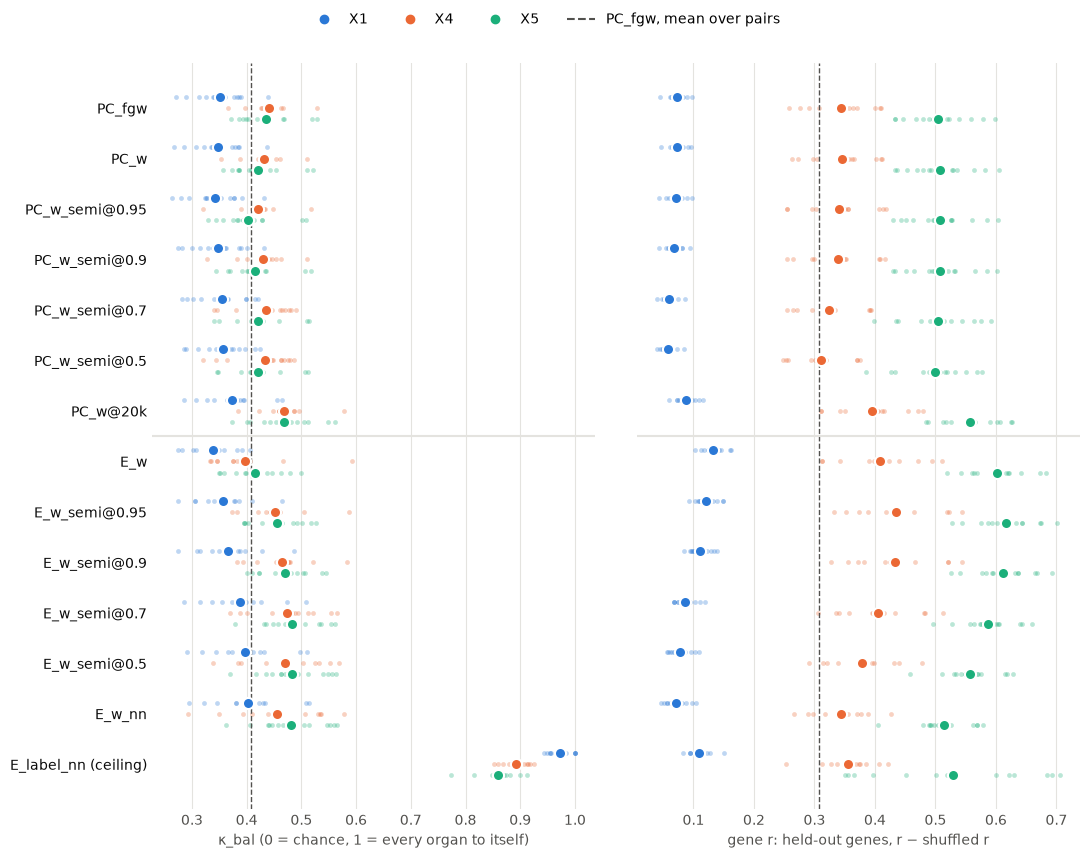

In [10]:
PAIR_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # categorical slots, fixed order
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
assert len(PAIRS) <= len(PAIR_COLORS), "more pairs than categorical slots: use small multiples instead"
pair_color = dict(zip(PAIRS, PAIR_COLORS))
fig, axes = plt.subplots(1, 2, figsize=(11, 0.5 * len(RUN_ORDER) + 1.6), sharey=True)
for ax, col, xlabel in ((axes[0], "kappa_bal", "κ_bal (0 = chance, 1 = every organ to itself)"),
                        (axes[1], "gene_r", "gene r: held-out genes, r − shuffled r")):
    for j, pid in enumerate(PAIRS):
        off = (j - (len(PAIRS) - 1) / 2) * 0.22
        for i, run in enumerate(RUN_ORDER):
            v = main[(main.run == run) & (main.pair == pid)][col].to_numpy()
            if len(v):
                ax.scatter(v, np.full(len(v), i + off), s=12, color=pair_color[pid], alpha=0.3, linewidths=0)
                ax.scatter([np.nanmean(v)], [i + off], s=64, color=pair_color[pid], edgecolors="white",
                           linewidths=1.5, zorder=3)
    ax.axvline(main[main.run == "PC_fgw"].groupby("pair")[col].mean().mean(), color=MUTED, ls="--", lw=1)
    ax.axhline(RUN_ORDER.index("E_w") - 0.5, color=GRID, lw=1.5)
    ax.set_xlabel(xlabel, color=MUTED)
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ax.spines.values():
        s.set_visible(False)
axes[0].set_yticks(range(len(RUN_ORDER)), [f"{r} (ceiling)" if "label" in r else r for r in RUN_ORDER], color=INK)
axes[0].invert_yaxis()
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=pair_color[p], label=p) for p in PAIRS]
           + [Line2D([], [], ls="--", color=MUTED, label="PC_fgw, mean over pairs")],
           loc="upper center", ncol=len(PAIRS) + 1, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.45 / fig.get_figheight()), w_pad=3)
plt.show()

## 4. Choosing τ_b without labels

The benchmark lets labels score a result but not choose a setting. Here τ_b of `E_w` (1, the values in `TAUS_B`, and 0 for `E_w_nn`) is chosen per pair and direction by **gene_r_sel**, gene r on the selection half of the held-out genes, and scored by κ_bal and by **gene_r_eval**, the other half. The oracle picks the τ_b with the best κ_bal; the **regret** is what the label-free choice gives up. A regret above 0.05 is flagged (the threshold of §2e in `docs/st_3d_alignment_strategies.md`). The last table chooses one τ_b for everything, by the mean gene_r_sel over all pairs and directions.

In [11]:
TB = {"E_w": 1.0, **{f"E_w_semi@{tb:g}": tb for tb in TAUS_B}, "E_w_nn": 0.0}
e = (res[res.run.isin(TB)].groupby(["pair", "direction", "run"])[["kappa_bal", "gene_r_sel", "gene_r_eval"]]
     .mean().reset_index())
pick = []
for (pid, d), g in e.groupby(["pair", "direction"]):
    by_r, by_k = g.loc[g.gene_r_sel.idxmax()], g.loc[g.kappa_bal.idxmax()]
    pick.append(dict(pair=pid, direction=d, tau_b=TB[by_r.run], kappa_bal=by_r.kappa_bal, gene_r_eval=by_r.gene_r_eval,
                     tau_b_oracle=TB[by_k.run], kappa_bal_oracle=by_k.kappa_bal,
                     regret=by_k.kappa_bal - by_r.kappa_bal))
pick = pd.DataFrame(pick)
pick["flag"] = np.where(pick.regret > 0.05, "regret > 0.05", "")
print("tau_b chosen by gene_r_sel, per pair and direction")
print(pick.round(3).to_string(index=False))

one = e.groupby("run")[["gene_r_sel", "kappa_bal", "gene_r_eval"]].mean().reindex(list(TB))
one.index = [f"{r} (tau_b {TB[r]:g})" for r in one.index]
print("\none tau_b for all pairs and directions (mean over them)")
print(one.round(3).to_string())
print(f"\nchosen by gene_r_sel: {one.gene_r_sel.idxmax()}; best kappa_bal: {one.kappa_bal.idxmax()}")

tau_b chosen by gene_r_sel, per pair and direction
pair direction  tau_b  kappa_bal  gene_r_eval  tau_b_oracle  kappa_bal_oracle  regret          flag
  X1   a_stack   1.00      0.331        0.138           0.0             0.349   0.018              
  X1   b_stack   1.00      0.343        0.132           0.0             0.430   0.087 regret > 0.05
  X4   a_stack   0.90      0.462        0.484           0.0             0.509   0.047              
  X4   b_stack   0.95      0.457        0.401           0.9             0.467   0.010              
  X5   a_stack   0.95      0.474        0.581           0.9             0.481   0.007              
  X5   b_stack   0.95      0.443        0.641           0.0             0.505   0.062 regret > 0.05

one tau_b for all pairs and directions (mean over them)
                            gene_r_sel  kappa_bal  gene_r_eval
E_w (tau_b 1)                    0.378      0.384        0.382
E_w_semi@0.95 (tau_b 0.95)       0.387      0.420        0.392
E_w

## 5. Feature variants

All variants are `E_w_semi@FEAT_TAU_B`, so `base` equals that row above. Δ is the change against `base` on the same pair. `drop_anti` chooses its PCs by the labels, so read it as a diagnostic: how much the PCs that contradict each other across species cost.

In [12]:
VARIANTS = ["feat:base", "feat:species_scale", "feat:whiten20", "feat:cosine", "feat:drop_anti"]
fv = res[res.kind == "feature variant"]
for col in ("kappa_bal", "gene_r"):
    t = per_pair(fv, col, VARIANTS)
    print(f"{col}\n{t.round(3).to_string()}")
    print(f"\nchange against base\n{(t - t.loc['feat:base']).round(3).to_string()}\n")

kappa_bal
pair                   X1     X4     X5   mean
run                                           
feat:base           0.366  0.465  0.471  0.434
feat:species_scale  0.369  0.469  0.478  0.439
feat:whiten20       0.267  0.383  0.388  0.346
feat:cosine         0.380  0.503  0.507  0.463
feat:drop_anti      0.392  0.464  0.467  0.441

change against base
pair                   X1     X4     X5   mean
run                                           
feat:base           0.000  0.000  0.000  0.000
feat:species_scale  0.003  0.004  0.007  0.005
feat:whiten20      -0.099 -0.082 -0.083 -0.088
feat:cosine         0.014  0.038  0.036  0.029
feat:drop_anti      0.025 -0.001 -0.004  0.007

gene_r
pair                   X1     X4     X5   mean
run                                           
feat:base           0.110  0.433  0.612  0.385
feat:species_scale  0.110  0.433  0.609  0.384
feat:whiten20       0.054  0.266  0.411  0.243
feat:cosine         0.110  0.434  0.608  0.384
feat:drop_anti      0

/tmp/ipykernel_3534347/1929888501.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  return t.assign(mean=t.mean(1))
/tmp/ipykernel_3534347/1929888501.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  return t.assign(mean=t.mean(1))


## 6. Cosine features and the τ_b sweep together

Sections 3 and 5 found the two largest gains separately: cosine distance (+0.03 at τ_b = 0.9) and a more relaxed target side (τ_b = 0.7 or below). Here they are combined: the whole-embryo runs with cosine distance over the full τ_b sweep, against the Euclidean ones and `PC_fgw`. `cos_w_semi@0.9` must reproduce `feat:cosine` of section 5. The results are cached per pair (`*_cosine.csv`); this section loads only the pair data, not the stacks.

In [ ]:
COS_RUNS = [(f"cos_w_semi@{tb:g}", tb, "features") for tb in TAUS_B] + [("cos_w_nn", 0.0, "features")]
cos = []
for pid in PAIRS:
    f = OUT / f"{pid}_seed{SEED}_tol{INNER_TOL:g}_{RUN_KEY}_cosine.csv"
    if f.exists() and not FORCE:
        cos.append(pd.read_csv(f))
        print(f"{pid}: cached ({f.name})")
        continue
    t0 = time.perf_counter()
    task = Task(cfg, PIPELINE, ser.pairs[pid], SEED, root)
    task.fgw = dataclasses.replace(task.fgw, inner_tol=INNER_TOL)
    Fa, Fb = (np.vstack([s.emb for s in task.data[side].values()]) for side in ("a", "b"))
    df = pd.DataFrame(run_whole(dict(pair=task.pair, task=task), COS_RUNS, metric="cosine",
                                scale=cost_scale(Fa, Fb, "cosine"), kind="cosine")).assign(pair=pid)
    df.to_csv(f, index=False)
    cos.append(df)
    print(f"{pid}: {len(df)} rows, {(time.perf_counter() - t0) / 60:.0f} min")
cos = pd.concat(cos, ignore_index=True)

chk = (cos[cos.run == f"cos_w_semi@{FEAT_TAU_B:g}"].set_index(["pair", "direction", "query"]).kappa_bal
       - res[res.run == "feat:cosine"].set_index(["pair", "direction", "query"]).kappa_bal)
print(f"cos_w_semi@{FEAT_TAU_B:g} vs feat:cosine: max |difference| in kappa_bal {chk.abs().max():.4f}\n")

COS_ORDER = (["PC_fgw"] + [f"E_w_semi@{tb:g}" for tb in TAUS_B] + ["E_w_nn"] + [r for r, _, _ in COS_RUNS]
             + ["E_label_nn"])
both = pd.concat([res[res.run.isin(COS_ORDER)], cos], ignore_index=True)
for col in ("kappa_bal", "gene_r"):
    print(f"{col} (mean over the query sections)\n{per_pair(both, col, COS_ORDER).round(3).to_string()}\n")
by_dir = both.groupby(["pair", "run", "direction"]).kappa_bal.mean().groupby(["pair", "run"]).mean()
print("kappa_bal, mean of the two direction means (the benchmark's convention)")
print(per_pair(by_dir.reset_index(), "kappa_bal", COS_ORDER).round(3).to_string())
k = both.groupby(["pair", "run"]).kappa_bal.mean().unstack().loc[list(PAIRS)]
print("\nkappa_bal against PC_fgw, per pair")
print(pd.DataFrame({r: k[r] - k.PC_fgw for r in COS_ORDER[1:-1]}).T.round(3).to_string())

## How to read the results

- **`PC_w` ≈ `PC_fgw`:** 3D geometry adds nothing to the cross-species step, as in 2D. Stage 1 (stack, gaps) and the field then serve no purpose here beyond the slab masses; the work goes to the marginals and the features.
- **`PC_fgw` clearly above `PC_w`:** 3D geometry helps where 2D geometry did not (no depth mismatch, no mirror ambiguity). Next: 3D FGW with the query side balanced.
- **`PC_w` below `E_w`:** the point cloud costs something the GW term does not explain. `PC_w_semi` shows the share of the two-sided τ, `PC_w@Nk` the share of the 6000-point resolution.
- **`E_w_semi@FEAT_TAU_B` against `PC_fgw` across the pairs:** whether the whole-embryo baseline holds beyond X4. It needs to win on most pairs before it replaces `PC_fgw` as the reference.
- **τ_b:** a small regret means τ_b can be set from the held-out genes; a large one, or a τ_b that differs by direction, means it needs a better criterion.
- **Feature variants:** a gain from `species_scale` or `whiten20` on most pairs is a cheap fix for the embedding; a large gain from `drop_anti` alone says the contradicting PCs matter and a label-free way to find them is worth building.